$\text{Extracting the data from the CSV files from the JPL NASA Horizons application}$

In [20]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt


#This class contains the initial position and velocity of the celestial body:

class body:
    def __init__(self,name,mass,pos,vel):
        self.name=name
        self.mass=mass
        self.pos=np.array(pos,dtype=float)
        self.vel=np.array(vel,dtype=float)
        
# Data from the NASA Horizons data :


b1 = body("Sun", 1988410e24, np.array([-1.602325979919614E+05,-7.005062866580029E+05 , -2.888835766883729E+05]), np.array([1.031902521729396E-02, 4.449029074274385E-03, 1.684369200411074E-03]))

b2 = body("Mercury", 3.302e23, np.array([5.005945338170964E+07, 9.740919593283530E+06, 8.434890081924666E+04]), np.array([-1.867497438964642E+01, 4.357107773137023E+01, 2.521169409511218E+01]))

b3 = body("Venus", 48.685e23, np.array([8.302432525358570E+07,6.425708656179664E+07 , 2.367777884417082E+07]), np.array([-2.247968325249581E+01,  2.391654264351647E+01,  1.218439937840489E+01]))

b4 = body("Earth", 5.97219e24, np.array([1.197286311109774E+08,  7.982463976381977E+07,  3.461601209038475E+07]), np.array([-1.805688133808997E+01,  2.195386395433621E+01,  9.517041959974549E+00]))

b5 = body("Mars", 6.4171e23, np.array([-3.932279784924307E+07,  2.124476993615854E+08,  9.853347780953923E+07]), np.array([-2.297156296757593E+01, -1.971991104355783E+00, -2.850371983145413E-01]))

b6 = body("Jupiter",18.9819e26 , np.array([ -5.469428826456959E+08,  5.251793803450833E+08,  2.384273303310489E+08]), np.array([-9.636786632066425E+00, -7.784841955694026E+00, -3.102163240189204E+00]))


bodies=[b1,b2,b3,b4,b5,b6]


N=len(bodies)

def acc(mass,pos):

    
    a=np.zeros((len(bodies),3))

    for i in range(len(bodies)):
        for j  in range(len(bodies)):

            
            if i!=j:
                G = 6.67430e-20
                
                r=pos[i]-pos[j]

                ax=-((G*mass[j]*r[0])/(np.linalg.norm(r)**3))
                ay=-((G*mass[j]*r[1])/(np.linalg.norm(r)**3))
                az=-((G*mass[j]*r[2])/(np.linalg.norm(r)**3))

                a[i]+=np.array([ax,ay,az])

    return a
                

            
def eq_o_mot(t,state):
    N=len(bodies)
    pos=state[:3*N].reshape(N,3)
    vel=state[3*N:].reshape(N,3)

    m=np.array([])
    for i in range(N):
        m=np.append(m,bodies[i].mass)

    ac=acc(m,pos)

    return np.concatenate((vel.flatten(),ac.flatten()))


initial_pos=np.array([])
initial_vel=np.array([])

for i in range(N):
    initial_pos=np.append(initial_pos,bodies[i].pos)
    initial_vel=np.append(initial_vel,bodies[i].vel)

state0=np.concatenate((initial_pos,initial_vel))

days=62

t_span = (0, days*24*3600)

t_eval = np.linspace(0, days*24*3600,50 )
    
sol=solve_ivp(eq_o_mot,t_span,state0,method='DOP853',t_eval=t_eval)



        

In [21]:
sol.y

array([[-1.60232598e+05, -1.59105059e+05, -1.57978653e+05, ...,
        -1.08848347e+05, -1.07798313e+05, -1.06750334e+05],
       [-7.00506287e+05, -7.00018941e+05, -6.99529648e+05, ...,
        -6.75417473e+05, -6.74837047e+05, -6.74254824e+05],
       [-2.88883577e+05, -2.88699012e+05, -2.88513590e+05, ...,
        -2.79221633e+05, -2.78994720e+05, -2.78766977e+05],
       ...,
       [-9.63678663e+00, -9.62100287e+00, -9.60519233e+00, ...,
        -8.86695866e+00, -8.84998018e+00, -8.83297772e+00],
       [-7.78484196e+00, -7.79999539e+00, -7.81512079e+00, ...,
        -8.46624631e+00, -8.48004911e+00, -8.49382248e+00],
       [-3.10216324e+00, -3.10904262e+00, -3.11591064e+00, ...,
        -3.41297090e+00, -3.41930045e+00, -3.42561797e+00]],
      shape=(36, 50))

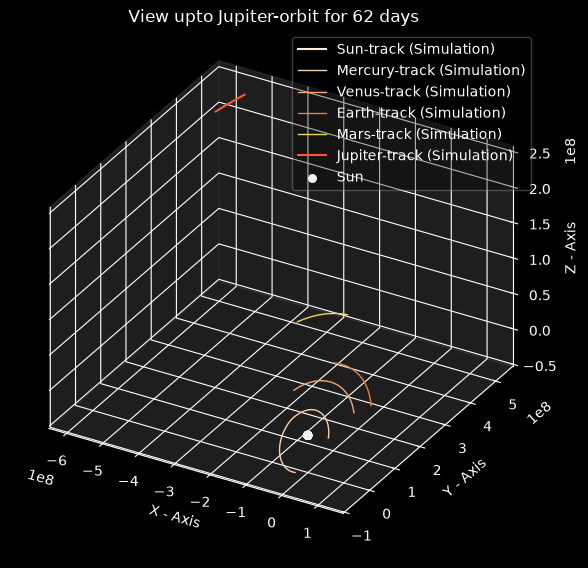

In [22]:
with plt.style.context("dark_background"):

    fig=plt.figure(figsize=(6,6))
    ax=fig.add_subplot(projection="3d")
    ax.set_title(f"View upto Jupiter-orbit for {days} days")
    ax.set_xlabel("X - Axis")
    ax.set_ylabel("Y - Axis")
    ax.set_zlabel("Z - Axis")
    # Set the background panel colors with a low alpha (e.g., 0.1 for 10% opacity)
    # Format is (Red, Green, Blue, Alpha)
    ax.xaxis.set_pane_color((0.2, 0.2, 0.2, 0.6))
    ax.yaxis.set_pane_color((0.2, 0.2, 0.2, 0.6))
    ax.zaxis.set_pane_color((0.2, 0.2, 0.2, 0.6))
    ax.set_proj_type('ortho')



    ax.plot(sol.y[0],sol.y[1],sol.y[2],color="#fff0df",label="Sun-track (Simulation)")
    ax.plot(sol.y[3],sol.y[4],sol.y[5],lw=1,color="#ffd0a6",label="Mercury-track (Simulation)")

    ax.plot(sol.y[6],sol.y[7],sol.y[8],lw=1,color="#f9a66c",label="Venus-track (Simulation)")
    ax.plot(sol.y[9],sol.y[10],sol.y[11],lw=1,color="#ed7d3a",label="Earth-track (Simulation)")
    ax.plot(sol.y[12],sol.y[13],sol.y[14],lw=1,color="#f4d35e",label="Mars-track (Simulation)")
    ax.plot(sol.y[15],sol.y[16],sol.y[17],lw=1.5,color="#f95738",label="Jupiter-track (Simulation)")
    
    
    ax.scatter(sol.y[0],sol.y[1],sol.y[2],s=30,color="#F3F3F3",label="Sun")

    ax.legend(framealpha=0.3,shadow=False,loc=1)
    plt.tight_layout()

    plt.show()

# $\text{Error-analysis}$

$\text{In this section I will be using the data from the .csv file of the planet Mercury and comparing the error in my simulation wrt the JPL data}$

In [23]:
import numpy as np
import pandas as pd

# Define column names for this Horizons file
column_names = [
    'JDTDB', 'Calendar_Date',
    'X', 'Y', 'Z',
    'VX', 'VY', 'VZ'
]

# Read the file and extract only the ephemeris data
data_lines = []

with open("/home/suparnajit2005/GitHub/Classical_mechanics_simulations/Central-force-motion/Data/NASA/horizons_results_mercury.csv", "r") as f:

    in_data_zone = False

    for line in f:

        if "$$EOE" in line:
            break

        if "$$SOE" in line:
            in_data_zone = True
            continue

        if in_data_zone:

            cleaned_line = line.strip().rstrip(',')

            if cleaned_line:
                row = [value.strip() for value in cleaned_line.split(',')]
                data_lines.append(row)


# Construct DataFrame
df = pd.DataFrame(data_lines, columns=column_names)

# Convert columns to appropriate data types
numeric_cols = [
    'JDTDB', 'X', 'Y', 'Z',
    'VX', 'VY', 'VZ'
]

df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric)

# Preview dataset
print(df.head(62))


# Convert DataFrame into NumPy array
Data_matrix = df.to_numpy()


# -----------------------------
# Time Initialisation
# -----------------------------

t0 = np.ones_like(Data_matrix.T[0], dtype=float) * np.min(Data_matrix.T[0])

t_days = Data_matrix.T[0].astype(float) - t0


# -----------------------------
# State Initialisation
# -----------------------------

JPL_data = np.array([
    Data_matrix.T[2].astype(float),  # X
    Data_matrix.T[3].astype(float),  # Y
    Data_matrix.T[4].astype(float),  # Z
    Data_matrix.T[5].astype(float),  # VX
    Data_matrix.T[6].astype(float),  # VY
    Data_matrix.T[7].astype(float)   # VZ
])

print("Time shape:", t_days.shape)
print("State shape:", JPL_data.shape)
print("Initial position:", JPL_data[:3, 0])
print("Initial velocity:", JPL_data[3:, 0])


        JDTDB                   Calendar_Date             X             Y  \
0   2461343.5  A.D. 2026-Oct-30 00:00:00.0000  5.005945e+07  9.740920e+06   
1   2461344.5  A.D. 2026-Oct-31 00:00:00.0000  4.826087e+07  1.346185e+07   
2   2461345.5  A.D. 2026-Nov-01 00:00:00.0000  4.609045e+07  1.707378e+07   
3   2461346.5  A.D. 2026-Nov-02 00:00:00.0000  4.354875e+07  2.054277e+07   
4   2461347.5  A.D. 2026-Nov-03 00:00:00.0000  4.064104e+07  2.383361e+07   
..        ...                             ...           ...           ...   
57  2461400.5  A.D. 2026-Dec-26 00:00:00.0000 -9.939735e+06 -6.201107e+07   
58  2461401.5  A.D. 2026-Dec-27 00:00:00.0000 -6.603849e+06 -6.213655e+07   
59  2461402.5  A.D. 2026-Dec-28 00:00:00.0000 -3.248948e+06 -6.208198e+07   
60  2461403.5  A.D. 2026-Dec-29 00:00:00.0000  1.151913e+05 -6.184651e+07   
61  2461404.5  A.D. 2026-Dec-30 00:00:00.0000  3.478653e+06 -6.142947e+07   

               Z         VX         VY         VZ  
0   8.434890e+04 -18.67

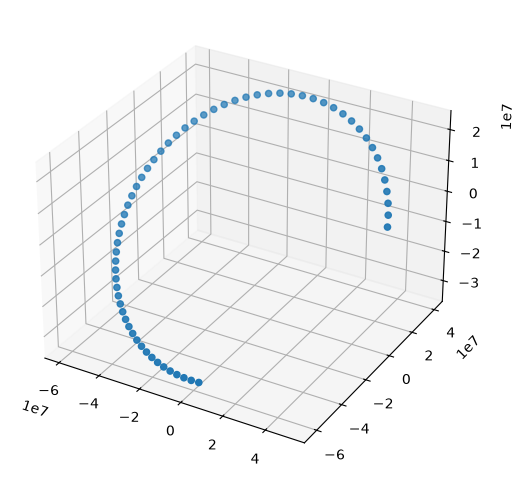

In [31]:
fig=plt.figure(figsize=(6,6))

ax=fig.add_subplot(projection="3d")

ax.scatter(JPL_data[0],JPL_data[1],JPL_data[2])

plt.show()

In [18]:
len(JPL_data[0])

62